# Data Analysis and Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("WineQT.csv")  # Replace with your file path if needed

# Preview data
print(df.shape)
df.head()

(1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
print("\n--- Info ---")
print(df.info())

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Summary Statistics ---")
print(df.describe())

# Check class distribution of quality
print("\n--- Quality Value Counts ---")
print(df['quality'].value_counts())


--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB
None

--- Missing Values ---
fixed acidity           0
volati

In [4]:
df = df.fillna(df.median())

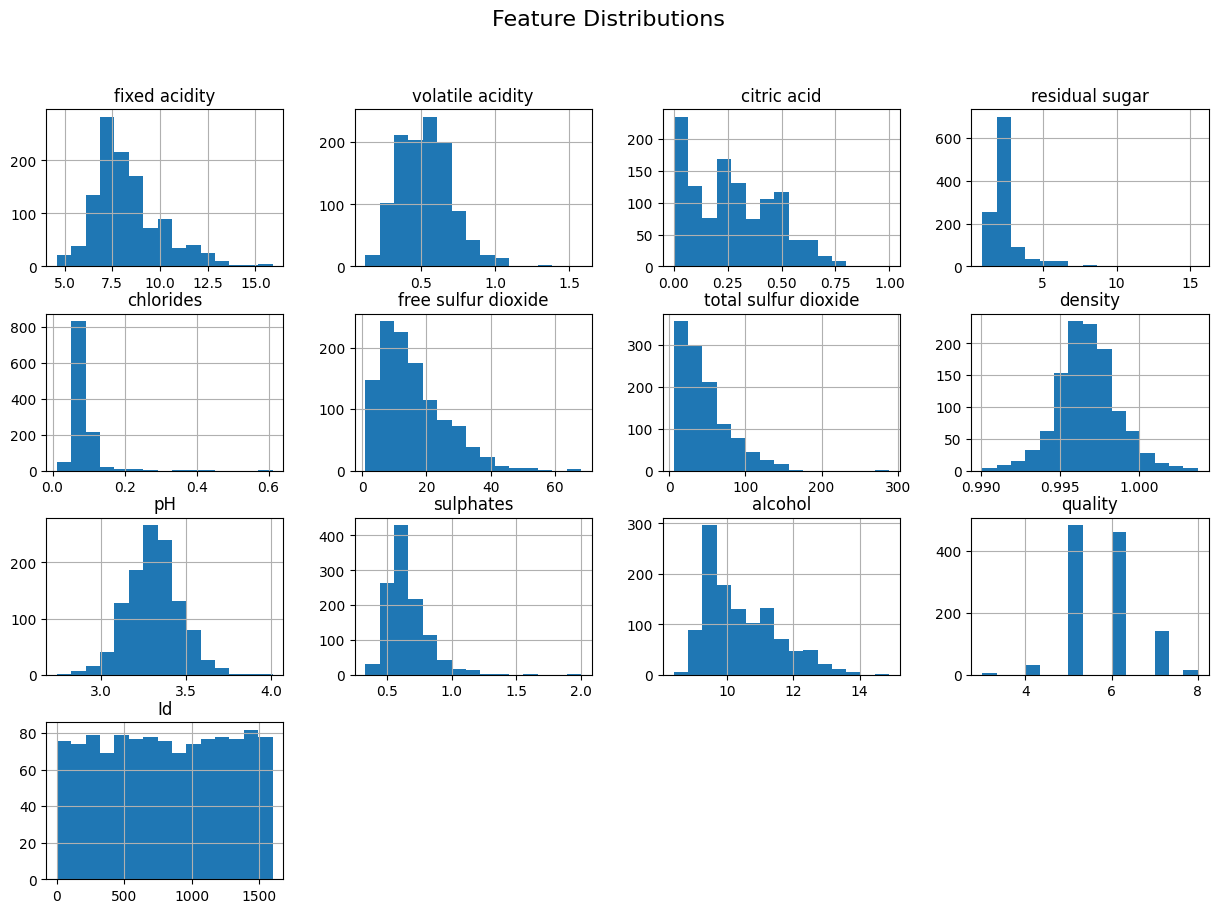

In [5]:
df.hist(bins=15, figsize=(15,10))
plt.suptitle("Feature Distributions", fontsize=16)
plt.show()

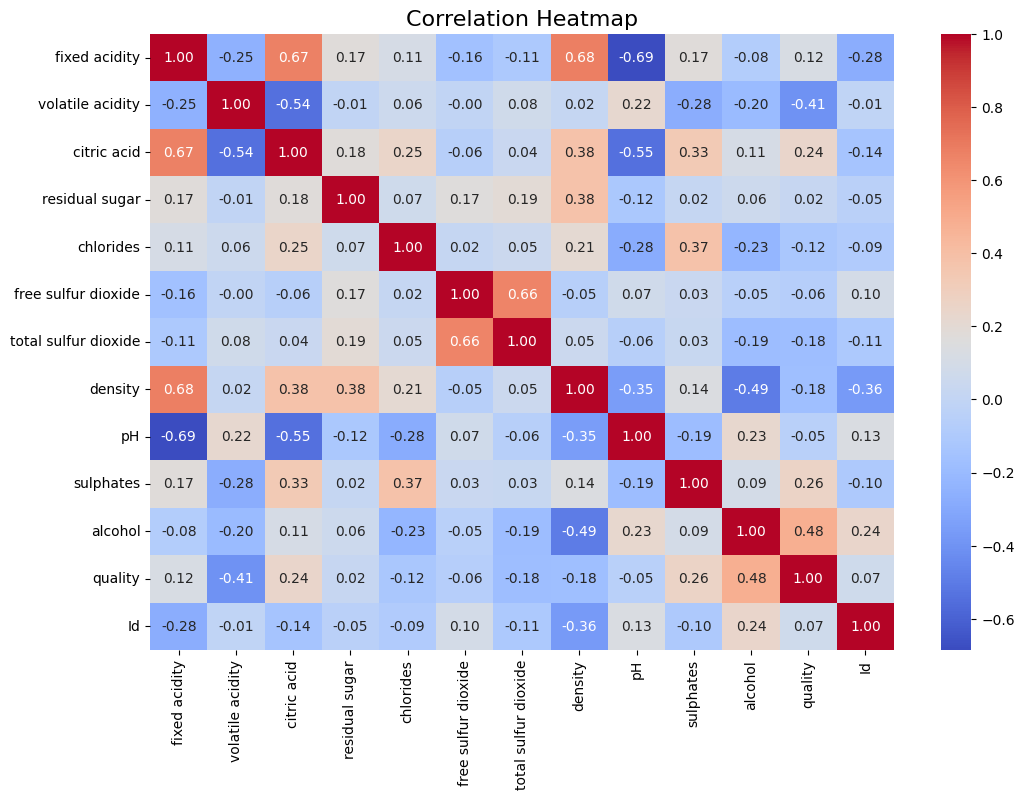

In [6]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap", fontsize=16)
plt.show()

/tmp/ipython-input-3967552696.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality', data=df, palette='viridis')


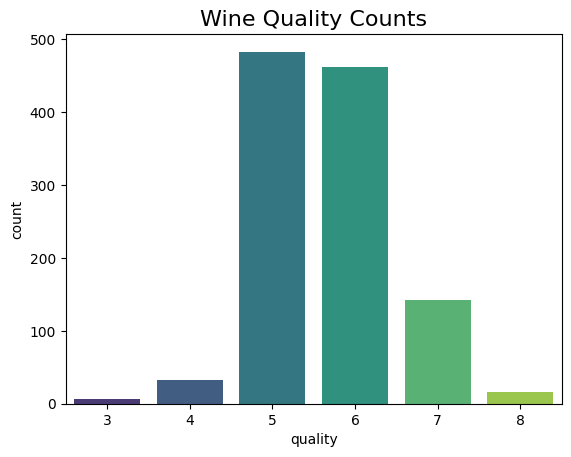

In [7]:
sns.countplot(x='quality', data=df, palette='viridis')
plt.title("Wine Quality Counts", fontsize=16)
plt.show()

/tmp/ipython-input-604731678.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y='alcohol', data=df, palette='coolwarm')


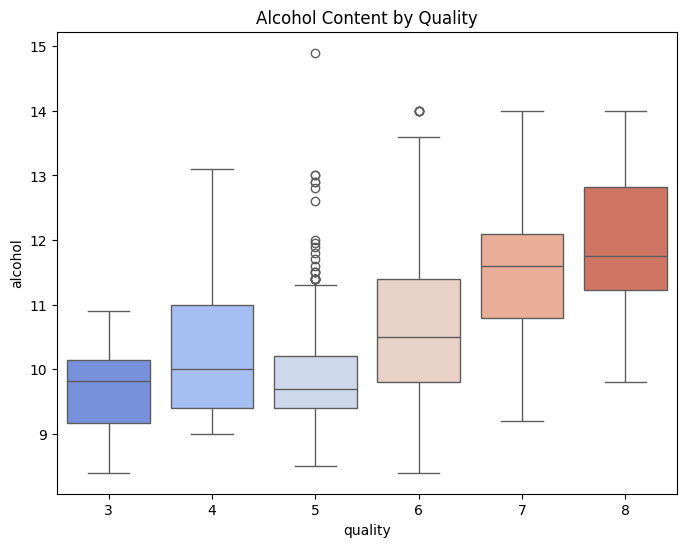

In [8]:
plt.figure(figsize=(8,6))
sns.boxplot(x='quality', y='alcohol', data=df, palette='coolwarm')
plt.title("Alcohol Content by Quality")
plt.show()

In [9]:
df = df.drop(columns=['Id'])

In [10]:
df['quality_label'] = (df['quality'] >= 7).astype(int)

In [11]:
X = df.drop(columns=['quality', 'quality_label'])
y = df['quality_label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (914, 11)
Testing set size: (229, 11)


# Model Training

In [13]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import joblib

In [14]:

# Binary target: good wine (>=7) vs not
df['quality_label'] = (df['quality'] >= 7).astype(int)

# Features & target
X = df.drop(columns=['quality', 'quality_label'])
y = df['quality_label']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

In [15]:
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42)
}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_results[name] = scores.mean()
    print(f"{name} CV Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")


Random Forest CV Accuracy: 0.9005 (+/- 0.0192)
Logistic Regression CV Accuracy: 0.8720 (+/- 0.0202)
SVM CV Accuracy: 0.8807 (+/- 0.0054)


In [16]:
best_model_name = max(cv_results, key=cv_results.get)
best_model = models[best_model_name]
print(f"\nBest Model: {best_model_name}")

# Train on full training set
best_model.fit(X_train, y_train)



Best Model: Random Forest


RandomForestClassifier(random_state=42)

In [17]:
y_pred = best_model.predict(X_test)
print("\nTest Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Test Accuracy: 0.9213973799126638

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.97      0.96       197
           1       0.79      0.59      0.68        32

    accuracy                           0.92       229
   macro avg       0.86      0.78      0.82       229
weighted avg       0.92      0.92      0.92       229



In [18]:
joblib.dump(best_model, f"{best_model_name.replace(' ', '_')}_model.pkl")
print(f"\nModel saved as {best_model_name.replace(' ', '_')}_model.pkl")

# Save the scaler too (important for predictions later)
joblib.dump(scaler, "scaler.pkl")
print("Scaler saved as scaler.pkl")


Model saved as Random_Forest_model.pkl
Scaler saved as scaler.pkl


# Create Streamlit App

In [19]:
!pip install streamlit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 95.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.0 MB/s eta 0:00:00


In [20]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load data & model
@st.cache_data
def load_data():
    df = pd.read_csv("WineQT.csv")
    return df

@st.cache_resource
def load_model():
    model = joblib.load("Random_Forest_model.pkl")  # Change if you saved another model
    scaler = joblib.load("scaler.pkl")
    return model, scaler

df = load_data()
model, scaler = load_model()

# ==============================
# Sidebar Navigation
# ==============================
st.sidebar.title("Navigation")
menu = st.sidebar.radio(
    "Go to:",
    ["📊 Data Exploration", "📈 Visualisation", "🔮 Model Prediction", "📉 Model Performance"]
)

st.title(" Wine Quality Prediction App")
st.markdown("""
This app uses machine learning to predict whether a wine is **Good** or **Not Good**
based on its chemical properties.
""")

2025-08-13 11:45:01.628 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2025-08-13 11:45:01.631 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2025-08-13 11:45:01.632 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-13 11:45:01.829 
  command:

    streamlit run /usr/local/lib/python3.11/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2025-08-13 11:45:01.830 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-13 11:45:01.831 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-13 11:45:01.832 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-13 11:45:01.842 Thread 'MainThread': missin

DeltaGenerator()

In [21]:
if menu == " Data Exploration":
    st.subheader("Dataset Overview")
    st.write("Shape:", df.shape)
    st.write("Columns:", list(df.columns))
    st.write(df.dtypes)

    st.subheader("Sample Data")
    st.write(df.head())

    st.subheader("Filter Data")
    quality_filter = st.slider("Select quality range", int(df['quality'].min()), int(df['quality'].max()), (3, 8))
    filtered_df = df[(df['quality'] >= quality_filter[0]) & (df['quality'] <= quality_filter[1])]
    st.write(f"Filtered data: {filtered_df.shape[0]} rows")
    st.dataframe(filtered_df)

In [22]:
if menu == " Visualisation":
    st.subheader("Data Visualisations")

    # 1. Histogram
    st.write("**Feature Distributions**")
    feature = st.selectbox("Select feature", df.columns[:-2])  # exclude quality & Id
    fig, ax = plt.subplots()
    sns.histplot(df[feature], kde=True, ax=ax)
    st.pyplot(fig)

    # 2. Correlation Heatmap
    st.write("**Correlation Heatmap**")
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
    st.pyplot(fig)

    # 3. Boxplot
    st.write("**Boxplot by Quality**")
    feature_box = st.selectbox("Select feature for boxplot", df.columns[:-2])
    fig, ax = plt.subplots()
    sns.boxplot(x="quality", y=feature_box, data=df, palette="coolwarm", ax=ax)
    st.pyplot(fig)

In [23]:
if menu == " Model Prediction":
    st.subheader("Make a Prediction")

    # Input features from user
    st.sidebar.subheader("Input Features")

    # Collect user input for each feature
    input_data = {}
    for col in X.columns:
        # Determine appropriate input type (number_input for numerical, selectbox for categorical if any)
        # For this dataset, all features are numerical
        min_val = float(df[col].min())
        max_val = float(df[col].max())
        mean_val = float(df[col].mean())

        input_data[col] = st.sidebar.number_input(
            f"{col.replace('_', ' ').title()}",
            min_value=min_val,
            max_value=max_val,
            value=mean_val,
            step=(max_val - min_val) / 100.0  # Provide a reasonable step
        )

    # Create a DataFrame from input data
    input_df = pd.DataFrame([input_data])

    st.subheader("Input Data")
    st.write(input_df)

    # Scale the input data
    input_scaled = scaler.transform(input_df)

    # Make prediction
    if st.button("Predict Quality"):
        prediction = model.predict(input_scaled)
        prediction_proba = model.predict_proba(input_scaled)

        st.subheader("Prediction Result")
        if prediction[0] == 1:
            st.success(f"Predicted Quality: Good Wine (Probability: {prediction_proba[0][1]:.2f})")
        else:
            st.error(f"Predicted Quality: Not Good Wine (Probability: {prediction_proba[0][0]:.2f})")

In [24]:
if menu == " Model Performance":
    st.subheader("Model Evaluation")

    st.write(f"**Best Model:** {best_model_name}")
    st.write(f"**Test Accuracy:** {accuracy_score(y_test, y_pred):.4f}")

    st.write("**Classification Report**")
    st.text(classification_report(y_test, y_pred))

    st.write("**Confusion Matrix**")
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    st.pyplot(fig)

    st.write("**Cross-Validation Results**")
    cv_df = pd.DataFrame.from_dict(cv_results, orient='index', columns=['Mean CV Accuracy'])
    st.dataframe(cv_df)